# Fine-tuning DistilBERT multilingue sur Allociné

**Projet From Training to Deployment.** Ce notebook fait les étapes 2 et 3 (entraînement + évaluation),
puis prépare les 3 fichiers attendus par l'API de déploiement (étape 4).

**Avant de lancer :** `Exécution > Modifier le type d'exécution > GPU T4`, puis `Exécution > Tout exécuter`.

Durée : environ 25 minutes sur un GPU T4. À la fin, un fichier `livrable_modele.zip` se télécharge.

In [1]:
# ===== Paramètres =====
MODEL_NAME = "distilbert-base-multilingual-cased"   # modèle choisi par le groupe
MAX_LEN    = 512        # longueur max en tokens (moyenne 147, seules 0,99 % des critiques dépassent 512)
TRAIN_SIZE = 20_000     # critiques d'entraînement (moitié positives, moitié négatives)
VAL_SIZE   = 5_000      # critiques de validation
# Mêmes hyperparamètres que la configuration de la phase 2
EPOCHS     = 2
BATCH      = 16
GRAD_ACC   = 2          # batch effectif = 16 x 2 = 32
LR         = 2e-5
WEIGHT_DECAY = 0.01
SEED       = 42
VERSION    = "v1.0"
DATA_URL   = ("https://raw.githubusercontent.com/ssabiridrissi-rgb/from-training-to-deployment/"
              "feature/data-preparation/data/processed/allocine_train_clean.csv")

In [2]:
# ===== Installation + GPU =====
!pip -q install datasets onnx onnxruntime onnxscript scikit-learn
import torch
print("GPU :", torch.cuda.get_device_name(0) if torch.cuda.is_available()
      else "AUCUN -> Exécution > Modifier le type d'exécution > GPU T4")

GPU : Tesla T4


## 1. Données
- **Entraînement :** le CSV nettoyé par la personne 1 (doublons et critiques contradictoires supprimés).
- **Validation et test :** les jeux officiels d'Allociné (20 000 critiques chacun), jamais vus pendant l'entraînement.

In [3]:
import time, json, os
import numpy as np, pandas as pd
from datasets import load_dataset, Dataset

T0 = time.time()
try:
    train_full = pd.read_csv(DATA_URL)
    SOURCE = "CSV nettoyé de la personne 1 (GitHub)"
except Exception as e:
    print("CSV indisponible, on prend le train Allociné de Hugging Face :", e)
    train_full = load_dataset("tblard/allocine", split="train").to_pandas().drop_duplicates("review")
    SOURCE = "tblard/allocine (train, sans doublons)"

hf = load_dataset("tblard/allocine")
val_full, test_df = hf["validation"].to_pandas(), hf["test"].to_pandas()

train_full = train_full.dropna(subset=["review", "label"])
train_full["label"] = train_full["label"].astype(int)
# Aucune critique de validation/test ne doit apparaître dans l'entraînement
seen = set(val_full["review"]) | set(test_df["review"])
train_full = train_full[~train_full["review"].isin(seen)]

# Échantillon équilibré : autant de positives que de négatives
train_df = pd.concat([g.sample(min(len(g), TRAIN_SIZE // 2), random_state=SEED)
                      for _, g in train_full.groupby("label")]).sample(frac=1, random_state=SEED)
val_df = val_full.sample(min(VAL_SIZE, len(val_full)), random_state=SEED)

print(f"Source : {SOURCE}")
print(f"Train : {len(train_df)} (sur {len(train_full)} dispo) | Val : {len(val_df)} | Test : {len(test_df)}")
print("Répartition train :", train_df["label"].value_counts().to_dict(), "(0 = négatif, 1 = positif)")

README.md:   0%|          | 0.00/9.31k [00:00<?, ?B/s]

allocine/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 60.0MB            

allocine/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

allocine/validation-00000-of-00001.parqu(…): reconstructing file:   0%|          |  0.00B / 7.58MB            

allocine/validation-00000-of-00001.parqu(…): downloading bytes:           |  0.00B            

allocine/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 7.58MB            

allocine/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/160000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/20000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/20000 [00:00<?, ? examples/s]

Source : CSV nettoyé de la personne 1 (GitHub)
Train : 20000 (sur 159416 dispo) | Val : 5000 | Test : 20000
Répartition train : {1: 10000, 0: 10000} (0 = négatif, 1 = positif)


## 2. Tokenization
Le tokenizer WordPiece découpe chaque critique en sous-mots (vocabulaire de 119 547 tokens),
ajoute `[CLS]` au début et `[SEP]` à la fin, et coupe à `MAX_LEN` tokens.

In [4]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained(MODEL_NAME)

def to_ds(df):
    ds = Dataset.from_pandas(df[["review", "label"]].reset_index(drop=True))
    return ds.map(lambda b: tok(b["review"], truncation=True, max_length=MAX_LEN),
                  batched=True, remove_columns=["review"])

train_ds, val_ds, test_ds = to_ds(train_df), to_ds(val_df), to_ds(test_df)
lens = np.array([len(x) for x in train_ds["input_ids"]])
print(f"Tokens par critique : moyenne {lens.mean():.0f}, médiane {np.median(lens):.0f}, "
      f"{(lens >= MAX_LEN).mean():.1%} coupées à {MAX_LEN}")
print("Exemple :", tok.convert_ids_to_tokens(train_ds[0]["input_ids"][:20]))

config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

Map:   0%|          | 0/20000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Map:   0%|          | 0/20000 [00:00<?, ? examples/s]

Tokens par critique : moyenne 147, médiane 107, 1.0% coupées à 512
Exemple : ['[CLS]', 'Audrey', 'Mar', '##nay', 'est', 'mer', '##vei', '##lle', '##use', ',', 'Jean', '-', 'Paul', 'R', '##ou', '##ve', 'est', 'st', '##up', '##é']


## 3. Fine-tuning
On part de DistilBERT multilingue pré-entraîné (6 couches Transformer, 12 têtes d'attention, 768 dimensions)
et on ajoute une couche de classification à 2 sorties (négatif / positif). Tous les poids sont ré-entraînés.

In [5]:
from transformers import (AutoModelForSequenceClassification, DataCollatorWithPadding,
                          Trainer, TrainingArguments, set_seed)
set_seed(SEED)
id2label = {0: "négatif", 1: "positif"}
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2, id2label=id2label, label2id={v: k for k, v in id2label.items()})
print(f"Paramètres : {sum(p.numel() for p in model.parameters()) / 1e6:.0f} M")

from sklearn.metrics import accuracy_score, f1_score

def compute_metrics(pred):
    p = pred.predictions.argmax(-1)
    return {"accuracy": accuracy_score(pred.label_ids, p), "f1": f1_score(pred.label_ids, p)}

steps = int(np.ceil(len(train_ds) / (BATCH * GRAD_ACC))) * EPOCHS
args = TrainingArguments(
    output_dir="runs", num_train_epochs=EPOCHS, learning_rate=LR, weight_decay=WEIGHT_DECAY,
    per_device_train_batch_size=BATCH, gradient_accumulation_steps=GRAD_ACC,
    per_device_eval_batch_size=128, warmup_steps=int(0.06 * steps), lr_scheduler_type="linear",
    fp16=torch.cuda.is_available(), logging_steps=max(1, steps // 40),
    eval_strategy="epoch", save_strategy="epoch", save_total_limit=2,
    load_best_model_at_end=True, metric_for_best_model="f1",   # meilleur checkpoint selon le F1
    report_to="none", seed=SEED)
trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                  data_collator=DataCollatorWithPadding(tok), compute_metrics=compute_metrics)
t = time.time()
trainer.train()
TRAIN_MIN = (time.time() - t) / 60
print(f"Entraînement terminé en {TRAIN_MIN:.1f} min")
os.makedirs("livrable", exist_ok=True)
with open("livrable/training_config.json", "w", encoding="utf-8") as f:
    json.dump({"model": MODEL_NAME, "max_length": MAX_LEN, "train_size": len(train_ds), "epochs": EPOCHS,
               "batch_size": BATCH, "gradient_accumulation": GRAD_ACC, "learning_rate": LR,
               "weight_decay": WEIGHT_DECAY, "seed": SEED, "selection": "f1",
               "labels": id2label}, f, ensure_ascii=False, indent=2)
with open("livrable/training_history.json", "w", encoding="utf-8") as f:
    json.dump(trainer.state.log_history, f, ensure_ascii=False, indent=2)
for h in trainer.state.log_history:
    if "eval_f1" in h:
        print(f"Époque {h['epoch']:.0f} : val accuracy {h['eval_accuracy']:.2%}, F1 {h['eval_f1']:.4f}")

model.safetensors: reconstructing file:   0%|          |  0.00B /  542MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Paramètres : 135 M


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.480558,0.228677,0.906000,0.909615
2,0.289712,0.195661,0.927600,0.927571


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Entraînement terminé en 9.0 min
Époque 1 : val accuracy 90.60%, F1 0.9096
Époque 2 : val accuracy 92.76%, F1 0.9276


## 4. Évaluation (jeu de test jamais vu)

{
  "model": "distilbert-base-multilingual-cased",
  "version": "v1.0",
  "data_source": "CSV nettoyé de la personne 1 (GitHub)",
  "train_size": 20000,
  "epochs": 2,
  "max_len": 512,
  "lr": 2e-05,
  "batch": 16,
  "grad_acc": 2,
  "train_minutes": 9.0,
  "val_accuracy": 0.9276,
  "test_accuracy": 0.9285,
  "test_f1": 0.9251,
  "test_roc_auc": 0.9798,
  "test_size": 20000
}
              precision    recall  f1-score   support

     négatif      0.927     0.936     0.932     10408
     positif      0.930     0.920     0.925      9592

    accuracy                          0.928     20000
   macro avg      0.929     0.928     0.928     20000
weighted avg      0.929     0.928     0.928     20000



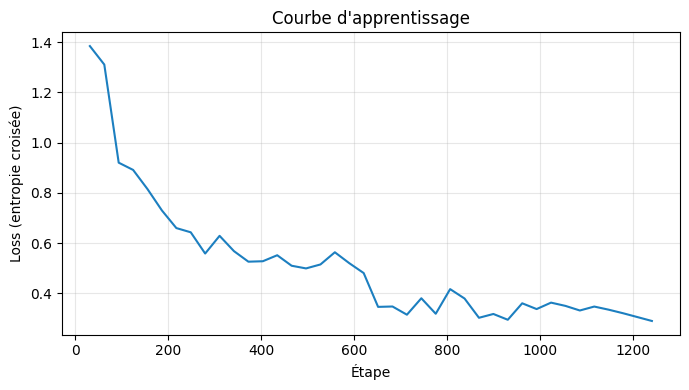

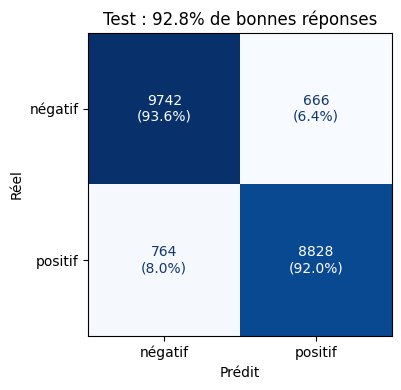

In [6]:
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report, roc_auc_score
import matplotlib.pyplot as plt

def evaluate(ds):
    out = trainer.predict(ds)
    logits = out.predictions
    probs = np.exp(logits - logits.max(1, keepdims=True)); probs /= probs.sum(1, keepdims=True)
    return out.label_ids, probs.argmax(1), probs

yv, pv, _ = evaluate(val_ds)
yt, pt, probs_t = evaluate(test_ds)
metrics = {
    "model": MODEL_NAME, "version": VERSION, "data_source": SOURCE,
    "train_size": len(train_ds), "epochs": EPOCHS, "max_len": MAX_LEN, "lr": LR, "batch": BATCH,
    "grad_acc": GRAD_ACC,
    "train_minutes": round(TRAIN_MIN, 1),
    "val_accuracy": round(accuracy_score(yv, pv), 4),
    "test_accuracy": round(accuracy_score(yt, pt), 4),
    "test_f1": round(f1_score(yt, pt), 4),
    "test_roc_auc": round(roc_auc_score(yt, probs_t[:, 1]), 4),
    "test_size": len(test_ds),
}
print(json.dumps(metrics, indent=2, ensure_ascii=False))
print(classification_report(yt, pt, target_names=["négatif", "positif"], digits=3))

os.makedirs("livrable/figures", exist_ok=True)
# Courbe de loss
hist = [h for h in trainer.state.log_history if "loss" in h]
plt.figure(figsize=(7, 4))
plt.plot([h["step"] for h in hist], [h["loss"] for h in hist], color="#1c7fc0")
plt.xlabel("Étape"); plt.ylabel("Loss (entropie croisée)"); plt.title("Courbe d'apprentissage")
plt.grid(alpha=.3); plt.tight_layout(); plt.savefig("livrable/figures/loss.png", dpi=200); plt.show()
# Matrice de confusion
cm = confusion_matrix(yt, pt)
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]}\n({cm[i, j] / cm[i].sum():.1%})", ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "#12356d")
ax.set_xticks([0, 1], ["négatif", "positif"]); ax.set_yticks([0, 1], ["négatif", "positif"])
ax.set_xlabel("Prédit"); ax.set_ylabel("Réel")
ax.set_title(f"Test : {metrics['test_accuracy']:.1%} de bonnes réponses")
plt.tight_layout(); plt.savefig("livrable/figures/confusion.png", dpi=200); plt.show()

In [7]:
# Quelques erreurs du modèle (utile pour la partie analyse / limites)
err = np.where(pt != yt)[0]
conf_err = probs_t[err].max(1)
for i in err[np.argsort(-conf_err)][:5]:
    print(f"Réel {id2label[yt[i]]:8s} | prédit {id2label[pt[i]]:8s} ({probs_t[i].max():.0%}) | "
          f"{test_df['review'].iloc[i][:140]}")

Réel positif  | prédit négatif  (100%) | Bon j'avoue qu'il faut aimer le genre et que pour beaucoup, le documentaire est synonyme d'ennui. Seulement, j'estime que si on se prétends 
Réel positif  | prédit négatif  (100%) | Un film si mauvais que ca en devient cosmique. Tout est raté dans ce film complêtement débil, les dialogues sont mauvais, la mise en scène e
Réel négatif  | prédit positif  (100%) | "Ceux qui restent" fut l'excellente surprise française de la rentrée 2008.Un film magnifique,à la fois pudique,sensible et puissant.Un vérit
Réel positif  | prédit négatif  (100%) | J'ai été très déçu par "Les fils de l'Homme", car il avait tout pour être bon : un bon réalisateur, des bons acteurs ( Clive Owen et Michael
Réel négatif  | prédit positif  (100%) | Excellent film, avec un Daniel Day Lewis des grands jours (quand ne joue-t-il pas bien ?). Quatre jeunes gens sont accusés d'un attentat qu'


## 5. Export pour le déploiement
Même procédure que `scripts/export_onnx.py` du repo : ONNX, quantization INT8 si elle ne fait pas
perdre de précision, vérification PyTorch = ONNX, puis `config.json` avec les statistiques de référence
utilisées par le monitoring (détection de data drift).

In [8]:
import onnxruntime as ort
from tokenizers import Tokenizer

trainer.save_model("checkpoint-final"); tok.save_pretrained("checkpoint-final")
OUT = "livrable/models"; os.makedirs(OUT, exist_ok=True)
tok.backend_tokenizer.save(f"{OUT}/tokenizer.json")

class LogitsOnly(torch.nn.Module):
    def __init__(self, m): super().__init__(); self.m = m
    def forward(self, input_ids, attention_mask):
        return self.m(input_ids=input_ids, attention_mask=attention_mask).logits

cpu_model = AutoModelForSequenceClassification.from_pretrained("checkpoint-final").eval()
dummy = tok("export example", return_tensors="pt")
kw = dict(input_names=["input_ids", "attention_mask"], output_names=["logits"], opset_version=17,
          dynamic_axes={"input_ids": {0: "batch", 1: "seq"}, "attention_mask": {0: "batch", 1: "seq"},
                        "logits": {0: "batch"}})
fp32 = f"{OUT}/model_fp32.onnx"
try:
    torch.onnx.export(LogitsOnly(cpu_model), (dummy["input_ids"], dummy["attention_mask"]), fp32,
                      dynamo=False, **kw)
except Exception as e:
    print("Export classique indisponible, export dynamo :", type(e).__name__)
    torch.onnx.export(LogitsOnly(cpu_model), (dummy["input_ids"], dummy["attention_mask"]), fp32,
                      dynamo=True, external_data=False, **kw)

from onnxruntime.quantization import QuantType, quantize_dynamic
int8 = f"{OUT}/model_int8.onnx"
quantize_dynamic(fp32, int8, weight_type=QuantType.QInt8)

# Même pipeline que l'API : tokenizer.json, pas de padding, troncature à MAX_LEN
api_tok = Tokenizer.from_file(f"{OUT}/tokenizer.json")
api_tok.no_padding(); api_tok.enable_truncation(max_length=MAX_LEN)

def run(path, texts):
    s = ort.InferenceSession(path, providers=["CPUExecutionProvider"])
    probs, ntok, ms = [], [], []
    for txt in texts:
        e = api_tok.encode(txt)
        t = time.perf_counter()
        lg = s.run(None, {"input_ids": np.array([e.ids], dtype=np.int64),
                          "attention_mask": np.array([e.attention_mask], dtype=np.int64)})[0][0]
        ms.append((time.perf_counter() - t) * 1000)
        p = np.exp(lg - lg.max()); probs.append(p / p.sum()); ntok.append(len(e.ids))
    return np.array(probs), np.array(ntok), np.array(ms)

sub = test_df.sample(min(2000, len(test_df)), random_state=SEED)
y_sub = sub["label"].to_numpy()
p32, ntok, ms32 = run(fp32, sub["review"])
p8, _, ms8 = run(int8, sub["review"])
acc32, acc8 = (p32.argmax(1) == y_sub).mean(), (p8.argmax(1) == y_sub).mean()
size32, size8 = os.path.getsize(fp32) / 1e6, os.path.getsize(int8) / 1e6
print(f"FP32 : {acc32:.2%} | {size32:.0f} Mo | {np.median(ms32):.0f} ms/critique")
print(f"INT8 : {acc8:.2%} | {size8:.0f} Mo | {np.median(ms8):.0f} ms/critique")

use_int8 = acc32 - acc8 <= 0.01          # on garde INT8 si on perd au plus 1 point
chosen, probs_ref = (int8, p8) if use_int8 else (fp32, p32)
os.replace(chosen, f"{OUT}/model.onnx")
for f in (fp32, int8):
    if os.path.exists(f): os.remove(f)
print("Modèle gardé :", "INT8" if use_int8 else "FP32")

# Vérification PyTorch == ONNX
s = ort.InferenceSession(f"{OUT}/model.onnx", providers=["CPUExecutionProvider"])
agree = 0
for txt in sub["review"].iloc[:200]:
    e = tok(txt, truncation=True, max_length=MAX_LEN, return_tensors="pt")
    with torch.no_grad():
        ref = cpu_model(**e).logits.numpy()
    got = s.run(None, {"input_ids": e["input_ids"].numpy(), "attention_mask": e["attention_mask"].numpy()})[0]
    agree += int(ref.argmax() == got.argmax())
print(f"PyTorch et ONNX d'accord sur {agree}/200 critiques")

metrics.update({
    "onnx_fp32": {"accuracy_2000": round(float(acc32), 4), "size_mb": round(size32, 1),
                  "median_ms": round(float(np.median(ms32)), 1)},
    "onnx_int8": {"accuracy_2000": round(float(acc8), 4), "size_mb": round(size8, 1),
                  "median_ms": round(float(np.median(ms8)), 1)},
    "deployed": "INT8" if use_int8 else "FP32",
    "pytorch_onnx_agreement": f"{agree}/200",
})

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

/tmp/ipykernel_1792/2752900681.py:20: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(LogitsOnly(cpu_model), (dummy["input_ids"], dummy["attention_mask"]), fp32,
/usr/local/lib/python3.13/dist-packages/transformers/masking_utils.py:208: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if (padding_length := kv_length + kv_offset - attention_mask.shape[-1]) > 0:
/usr/local/lib/python3.13/dist-packages/transformers/integrations/s

FP32 : 93.65% | 541 Mo | 121 ms/critique
INT8 : 91.65% | 136 Mo | 84 ms/critique
Modèle gardé : FP32
PyTorch et ONNX d'accord sur 194/200 critiques


In [9]:
# config.json lu par l'API + phrases de la démo
EXAMPLES = [
    "Ce film est magnifique, j'ai adoré ! Les acteurs sont excellents.",
    "Une histoire décevante et un film ennuyeux. J'ai failli partir avant la fin.",
    "Pas mal du tout, je ne m'attendais pas à passer un aussi bon moment.",
    "Génial, encore un remake inutile. Bravo, vraiment.",
    "Le début est lent, mais la deuxième moitié rattrape largement le tout.",
]
cfg = {
    "labels": ["négatif", "positif"],
    "max_length": MAX_LEN,
    "version": VERSION,
    "examples": EXAMPLES,
    "reference": {  # stats sur le jeu de test, pour détecter le data drift en production
        "mean_tokens": round(float(ntok.mean()), 2),
        "mean_confidence": round(float(probs_ref.max(1).mean()), 4),
    },
}
with open(f"{OUT}/config.json", "w", encoding="utf-8") as f:
    json.dump(cfg, f, ensure_ascii=False, indent=2)

demo_p, _, _ = run(f"{OUT}/model.onnx", EXAMPLES)
metrics["demo"] = []
for txt, p in zip(EXAMPLES, demo_p):
    lab = cfg["labels"][int(p.argmax())]
    metrics["demo"].append({"text": txt, "label": lab, "confidence": round(float(p.max()), 4)})
    print(f"{lab:8s} {p.max():6.1%}  {txt}")
print(json.dumps(cfg["reference"], indent=2))

positif   99.5%  Ce film est magnifique, j'ai adoré ! Les acteurs sont excellents.
négatif   99.6%  Une histoire décevante et un film ennuyeux. J'ai failli partir avant la fin.
positif   98.2%  Pas mal du tout, je ne m'attendais pas à passer un aussi bon moment.
négatif   68.6%  Génial, encore un remake inutile. Bravo, vraiment.
négatif   98.5%  Le début est lent, mais la deuxième moitié rattrape largement le tout.
{
  "mean_tokens": 148.4,
  "mean_confidence": 0.9522
}


In [10]:
# ===== Téléchargement =====
metrics["total_minutes"] = round((time.time() - T0) / 60, 1)
with open("livrable/metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)
import shutil
shutil.make_archive("livrable_modele", "zip", "livrable")
print(json.dumps({k: v for k, v in metrics.items() if k != "demo"}, indent=2, ensure_ascii=False))
print("Contenu :", sorted(os.listdir("livrable")), sorted(os.listdir("livrable/models")))
try:
    from google.colab import files
    files.download("livrable_modele.zip")
except ImportError:
    print("Pas sur Colab : le fichier est livrable_modele.zip")

{
  "model": "distilbert-base-multilingual-cased",
  "version": "v1.0",
  "data_source": "CSV nettoyé de la personne 1 (GitHub)",
  "train_size": 20000,
  "epochs": 2,
  "max_len": 512,
  "lr": 2e-05,
  "batch": 16,
  "grad_acc": 2,
  "train_minutes": 9.0,
  "val_accuracy": 0.9276,
  "test_accuracy": 0.9285,
  "test_f1": 0.9251,
  "test_roc_auc": 0.9798,
  "test_size": 20000,
  "onnx_fp32": {
    "accuracy_2000": 0.9365,
    "size_mb": 541.4,
    "median_ms": 120.7
  },
  "onnx_int8": {
    "accuracy_2000": 0.9165,
    "size_mb": 135.7,
    "median_ms": 83.7
  },
  "deployed": "FP32",
  "pytorch_onnx_agreement": "194/200",
  "total_minutes": 24.9
}
Contenu : ['figures', 'metrics.json', 'models', 'training_config.json', 'training_history.json'] ['config.json', 'model.onnx', 'tokenizer.json']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>